# 04b Temporal Drift, Fraud Rate and Label Delay

This notebook looks at how both datasets change over time, to motivate and size the
time-related parts of the model ladder:

| Question | Why it matters | Section |
|---|---|---|
| How large is each dataset, and how imbalanced? | Data section of the report; class weights in M1 | 1 |
| Does the fraud rate change over time (prior drift)? | Motivates sliding-window retraining in M2 | 2 |
| Do the feature distributions change over time (covariate drift)? | TA check: KS/PSI per time window, to compare later with model performance per window | 3 |
| Does the link between a feature and fraud change (concept drift)? | Separates "the data looks different" from "fraud behaves differently" | 4 |
| How much data and fraud falls in the 7-day label-delay window? | Sizes the unlabelled data that M3 can use | 5 |

All statistics use the training files only (`fraudTrain.csv` for Sparkov, the labelled
`train_transaction.csv` for IEEE-CIS). Figures are saved to `reports/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import ks_2samp

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path("../data/raw")
INTERIM_DIR = Path("../data/interim")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

SPARKOV_TRAIN_PATH = DATA_DIR / "fraudTrain.csv"
IEEE_TRANSACTION_PATH = DATA_DIR / "train_transaction.csv"
IEEE_CARD_ID_PATH = INTERIM_DIR / "ieee_card_id.csv"   # produced by notebook 03 (optional)

LABEL_DELAY_DAYS = 7      # labels of the latest 7 days are assumed unavailable (proposal)
REFERENCE_WEEKS = 4       # first weeks used as the reference distribution for drift

## 0. Load data and build a common time axis

Both datasets get a `day` column (days since the first transaction) and a `week` column, so
that the same weekly analysis runs on both. IEEE-CIS `TransactionDT` is a time delta in
seconds from an unknown reference date, so only relative time is used.

In [2]:
sparkov = pd.read_csv(SPARKOV_TRAIN_PATH)
sparkov["timestamp"] = pd.to_datetime(sparkov["trans_date_trans_time"])
sparkov["day"] = (sparkov["timestamp"] - sparkov["timestamp"].min()).dt.days
sparkov["week"] = sparkov["day"] // 7
sparkov["age"] = (sparkov["timestamp"] - pd.to_datetime(sparkov["dob"])).dt.days / 365.25
sparkov["hour"] = sparkov["timestamp"].dt.hour
lat1, lon1, lat2, lon2 = (np.radians(sparkov[c]) for c in ["lat", "long", "merch_lat", "merch_long"])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
sparkov["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
sparkov["label"] = sparkov["is_fraud"]

ieee_cols = (["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD", "card4", "card6"]
             + [f"C{i}" for i in range(1, 15)] + [f"D{i}" for i in (1, 2, 3, 4, 10, 15)])
ieee = pd.read_csv(IEEE_TRANSACTION_PATH, usecols=ieee_cols)
ieee["day"] = ((ieee["TransactionDT"] - ieee["TransactionDT"].min()) // 86400).astype(int)
ieee["week"] = ieee["day"] // 7
ieee["label"] = ieee["isFraud"]

DATASETS = {"Sparkov": sparkov, "IEEE-CIS": ieee}
for name, df in DATASETS.items():
    print(f"{name}: {len(df):,} rows, days 0-{df['day'].max()}, weeks 0-{df['week'].max()}")

Sparkov: 1,296,675 rows, days 0-537, weeks 0-76
IEEE-CIS: 590,540 rows, days 0-181, weeks 0-25


## 1. Dataset overview

In [3]:
def overview_row(name, df, raw_columns, entity_count):
    return {
        "dataset": name,
        "transactions": len(df),
        "frauds": int(df["label"].sum()),
        "fraud rate (%)": round(100 * df["label"].mean(), 3),
        "legit per fraud": round((1 - df["label"].mean()) / df["label"].mean(), 1),
        "days covered": int(df["day"].max()) + 1,
        "raw columns": raw_columns,
        "cards": entity_count,
    }


ieee_cards = None
if IEEE_CARD_ID_PATH.exists():
    card_ids = pd.read_csv(IEEE_CARD_ID_PATH)
    ieee = ieee.merge(card_ids, on="TransactionID", how="left")
    DATASETS["IEEE-CIS"] = ieee
    ieee_cards = int(ieee["card_id"].nunique())
else:
    print("ieee_card_id.csv not found: run notebook 03 first to add the IEEE-CIS card count")

overview = pd.DataFrame([
    overview_row("Sparkov (fraudTrain)", sparkov, 23, int(sparkov["cc_num"].nunique())),
    overview_row("IEEE-CIS (train_transaction)", ieee, 394, ieee_cards),
])
overview

,dataset,transactions,frauds,fraud rate (%),legit per fraud,days covered,raw columns,cards
0,Sparkov (fraudTrain),1296675,7506,0.579,171.8,538,23,983
1,IEEE-CIS (train_transaction),590540,20663,3.499,27.6,182,394,222572


## 2. Transaction volume and fraud rate over time (prior drift)

If the share of fraud moves a lot from week to week, a model trained on one period meets a
different class balance later. This is one reason for sliding-window retraining (M2) and for
reporting metrics per time window.

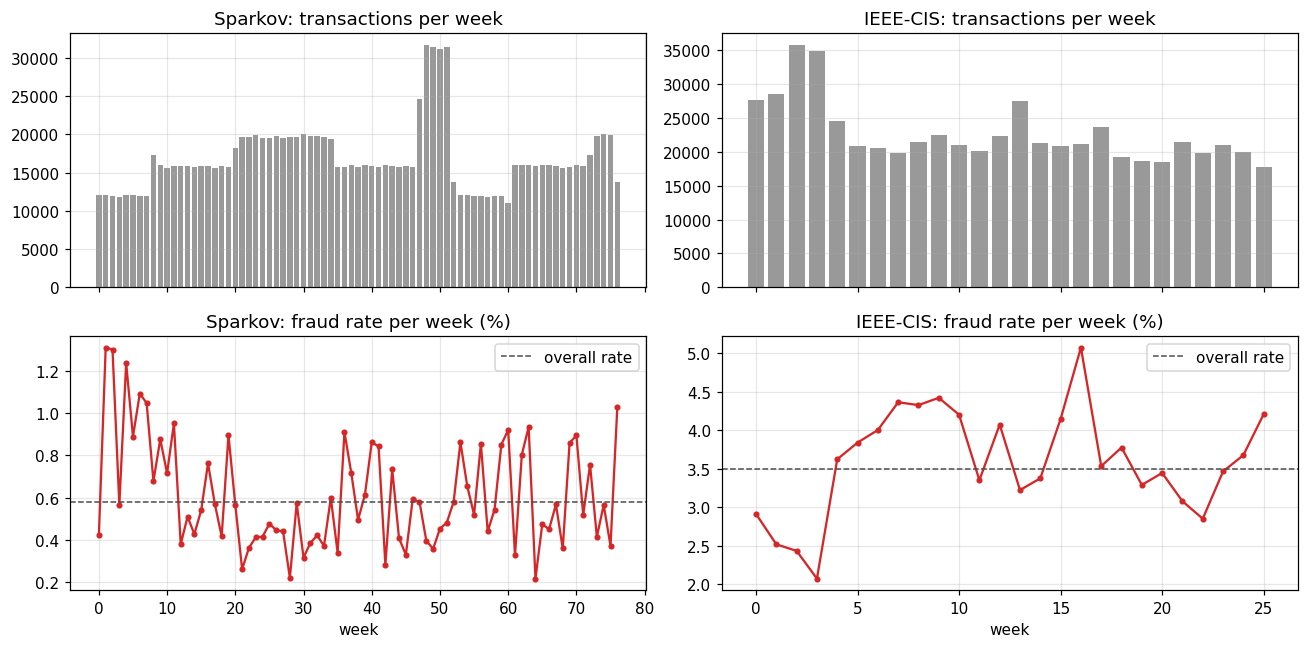

,weekly fraud rate min (%),weekly fraud rate median (%),weekly fraud rate max (%),max / min ratio
Sparkov,0.215,0.565,1.313,6.1
IEEE-CIS,2.074,3.578,5.072,2.4


In [4]:
def weekly_summary(df):
    g = df.groupby("week")["label"].agg(transactions="size", frauds="sum")
    g["fraud_rate_pct"] = 100 * g["frauds"] / g["transactions"]
    return g


fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex="col")
weekly = {}
for j, (name, df) in enumerate(DATASETS.items()):
    w = weekly_summary(df)
    weekly[name] = w
    axes[0, j].bar(w.index, w["transactions"], color="0.6")
    axes[0, j].set_title(f"{name}: transactions per week")
    axes[1, j].plot(w.index, w["fraud_rate_pct"], marker=".", color="tab:red")
    axes[1, j].axhline(100 * df["label"].mean(), color="0.3", ls="--", lw=1, label="overall rate")
    axes[1, j].set_title(f"{name}: fraud rate per week (%)")
    axes[1, j].set_xlabel("week")
    axes[1, j].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04b_volume_and_fraud_rate_by_week.png", bbox_inches="tight")
plt.show()

pd.DataFrame({name: {
    "weekly fraud rate min (%)": round(w["fraud_rate_pct"].min(), 3),
    "weekly fraud rate median (%)": round(w["fraud_rate_pct"].median(), 3),
    "weekly fraud rate max (%)": round(w["fraud_rate_pct"].max(), 3),
    "max / min ratio": round(w["fraud_rate_pct"].max() / max(w["fraud_rate_pct"].min(), 1e-9), 1),
} for name, w in weekly.items()}).T

## 3. Feature drift per week: PSI and KS against a reference period

For each feature and each week, the distribution is compared with the first
`REFERENCE_WEEKS` weeks:

- **PSI** (Population Stability Index): values are binned at the reference deciles, and
  PSI = sum over bins of (current share - reference share) * ln(current share / reference share).
  Common reading: below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 large shift.
  Missing values get their own bin, which matters for the IEEE-CIS D columns.
- **KS**: the largest gap between the two cumulative distributions (0 = identical, 1 = no overlap).

These weekly series are what the TA asked us to compare with model performance per window
once M0 and M1 results exist.

In [5]:
def psi(reference, current, bins=10, eps=1e-4):
    ref = pd.Series(reference, dtype=float)
    cur = pd.Series(current, dtype=float)
    edges = np.unique(np.nanquantile(ref.dropna(), np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:                      # almost constant feature: compare value shares instead
        edges = np.unique(np.concatenate([edges, [edges[-1] + 1]]))
    edges[0], edges[-1] = -np.inf, np.inf

    def shares(s):
        counts = np.histogram(s.dropna(), bins=edges)[0].astype(float)
        counts = np.append(counts, s.isna().sum())      # missing values = extra bin
        return np.clip(counts / max(len(s), 1), eps, None)

    r, c = shares(ref), shares(cur)
    return float(np.sum((c - r) * np.log(c / r)))


def weekly_drift(df, features, reference_weeks=REFERENCE_WEEKS):
    ref = df[df["week"] < reference_weeks]
    rows = []
    for week, cur in df[df["week"] >= reference_weeks].groupby("week"):
        for f in features:
            x, y = ref[f].dropna(), cur[f].dropna()
            rows.append({"week": week, "feature": f, "psi": psi(ref[f], cur[f]),
                         "ks": ks_2samp(x, y).statistic if len(x) > 20 and len(y) > 20 else np.nan})
    return pd.DataFrame(rows)


DRIFT_FEATURES = {
    "Sparkov": ["amt", "city_pop", "age", "hour", "distance_km"],
    "IEEE-CIS": ["TransactionAmt"] + [f"C{i}" for i in (1, 2, 5, 8, 9, 10, 13, 14)] + [f"D{i}" for i in (1, 2, 4, 10, 15)],
}
drift = {name: weekly_drift(df, DRIFT_FEATURES[name]) for name, df in DATASETS.items()}

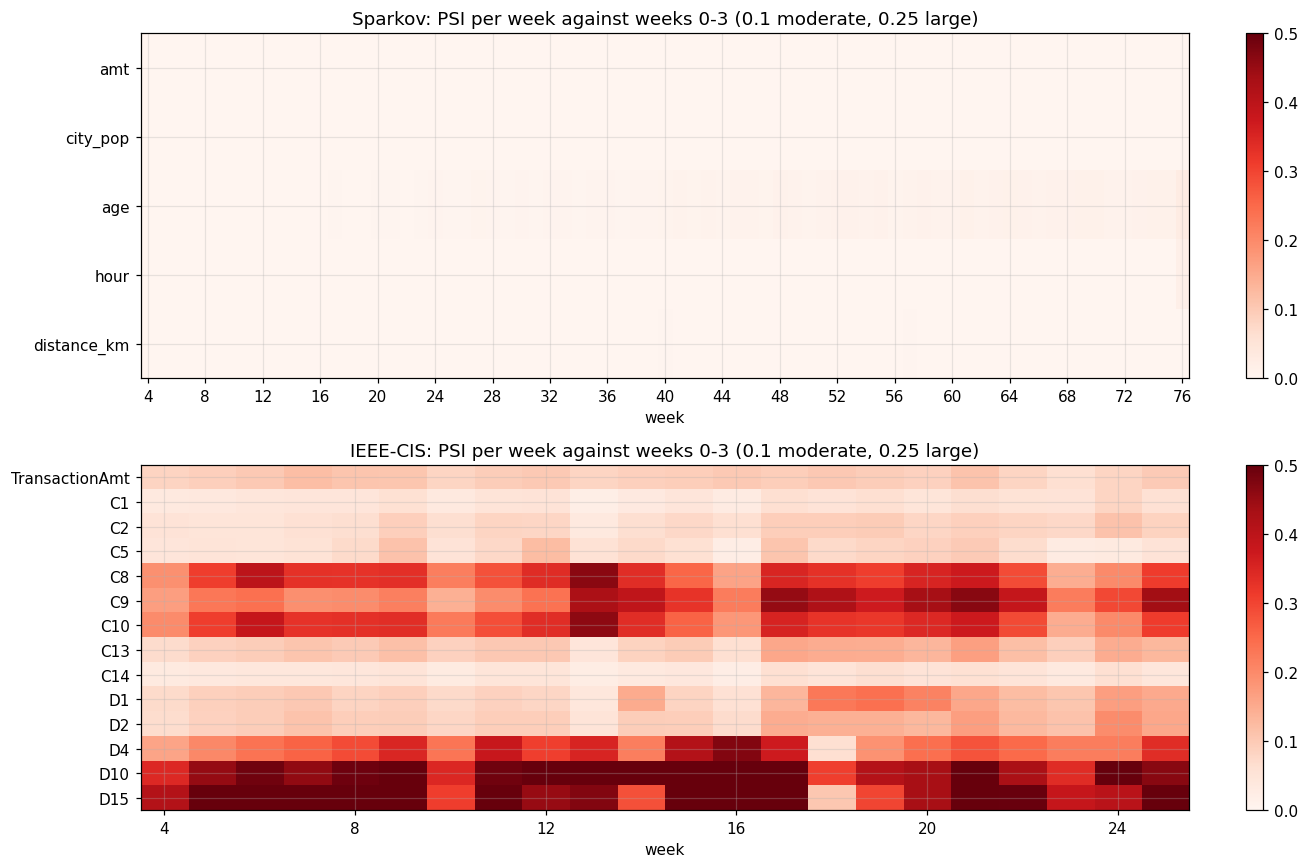

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, (name, d) in zip(axes, drift.items()):
    grid = d.pivot(index="feature", columns="week", values="psi").reindex(DRIFT_FEATURES[name])
    im = ax.imshow(grid.to_numpy(), aspect="auto", cmap="Reds", vmin=0, vmax=0.5)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xticks(range(0, grid.shape[1], 4), grid.columns[::4])
    ax.set_title(f"{name}: PSI per week against weeks 0-{REFERENCE_WEEKS - 1} (0.1 moderate, 0.25 large)")
    ax.set_xlabel("week")
    fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "04b_psi_heatmap_by_week.png", bbox_inches="tight")
plt.show()

In [7]:
def drift_summary(d):
    s = d.groupby("feature").agg(mean_psi=("psi", "mean"), max_psi=("psi", "max"),
                                 weeks_psi_over_0_25=("psi", lambda v: int((v > 0.25).sum())),
                                 mean_ks=("ks", "mean"), max_ks=("ks", "max"))
    return s.sort_values("mean_psi", ascending=False).round(3)


for name, d in drift.items():
    print(name)
    display(drift_summary(d))
    d.to_csv(f"../reports/04b_weekly_drift_{name.lower().replace('-', '_')}.csv", index=False)

Sparkov


,mean_psi,max_psi,weeks_psi_over_0_25,mean_ks,max_ks
feature,,,,,
age,0.006,0.026,0,0.030,0.065
distance_km,0.001,0.002,0,0.008,0.017
hour,0.001,0.016,0,0.007,0.062
amt,0.001,0.002,0,0.008,0.021
city_pop,0.001,0.001,0,0.008,0.015


IEEE-CIS


,mean_psi,max_psi,weeks_psi_over_0_25,mean_ks,max_ks
feature,,,,,
D15,0.482,0.660,21,0.117,0.162
D10,0.466,0.615,22,0.078,0.111
C9,0.303,0.467,11,0.258,0.317
C10,0.302,0.461,17,0.244,0.292
C8,0.300,0.465,17,0.245,0.297
D4,0.274,0.471,11,0.089,0.127
D1,0.119,0.238,0,0.157,0.197
D2,0.111,0.197,0,0.081,0.107
C13,0.109,0.166,0,0.156,0.193


## 4. Covariate drift versus concept drift

Section 3 shows whether the *inputs* change. Concept drift means the *relationship* between
an input and fraud changes. A simple check: split the timeline into an early and a late half
and compare the fraud rate within the same feature bins. If the bins keep their fraud rates,
the shift is mostly covariate drift; if the rates move, the concept itself changed.

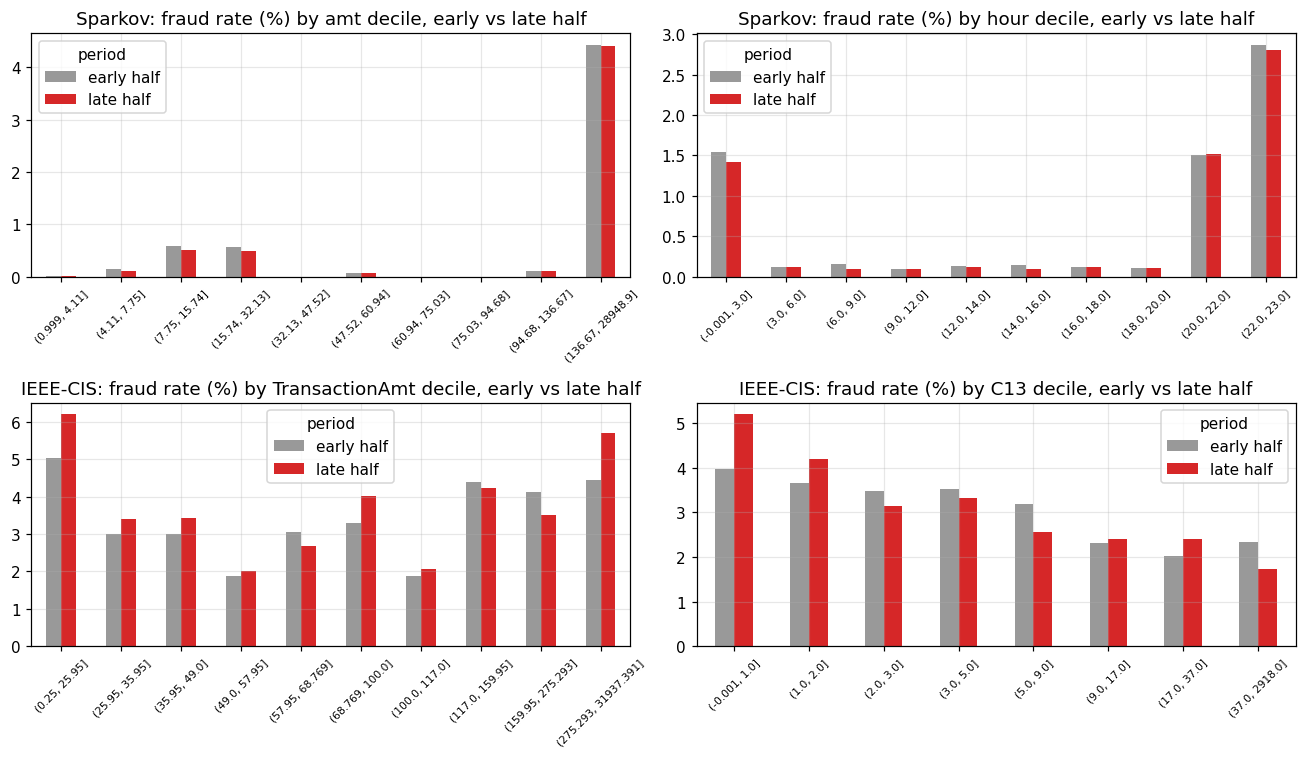

In [8]:
def fraud_rate_by_bin(df, feature, bins=10):
    data = df[[feature, "label", "day"]].dropna()
    edges = np.unique(np.quantile(data[feature], np.linspace(0, 1, bins + 1)))
    data["bin"] = pd.cut(data[feature], edges, include_lowest=True, duplicates="drop")
    half = data["day"] >= data["day"].median()
    data["period"] = np.where(half, "late half", "early half")
    table = data.groupby(["bin", "period"], observed=True)["label"].mean().unstack() * 100
    return table.round(2)


CONCEPT_FEATURES = {"Sparkov": ["amt", "hour"], "IEEE-CIS": ["TransactionAmt", "C13"]}
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, (name, df) in enumerate(DATASETS.items()):
    for j, f in enumerate(CONCEPT_FEATURES[name]):
        t = fraud_rate_by_bin(df, f)
        t.plot(kind="bar", ax=axes[i, j], color=["0.6", "tab:red"], rot=45)
        axes[i, j].set_title(f"{name}: fraud rate (%) by {f} decile, early vs late half")
        axes[i, j].set_xlabel("")
        axes[i, j].tick_params(axis="x", labelsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "04b_concept_drift_bins.png", bbox_inches="tight")
plt.show()

## 5. Label delay: how much falls in the latest 7 days?

The proposal assumes labels arrive 7 days late, so at any retraining time the latest 7 days
are unlabelled (all of them, not only the frauds). The table below uses the end of each
dataset's chronological training split (first 80% of time, as in the baseline) as the
retraining time, and also averages over every weekly retraining point.

In [9]:
def delay_window_stats(df, cutoff_day, delay=LABEL_DELAY_DAYS):
    seen = df[df["day"] < cutoff_day]
    hidden = seen[seen["day"] >= cutoff_day - delay]
    return {
        "transactions before cutoff": len(seen),
        "hidden (last 7 days)": len(hidden),
        "hidden share of transactions (%)": round(100 * len(hidden) / len(seen), 2),
        "frauds before cutoff": int(seen["label"].sum()),
        "hidden frauds": int(hidden["label"].sum()),
        "hidden share of frauds (%)": round(100 * hidden["label"].sum() / max(seen["label"].sum(), 1), 2),
        "fraud rate in hidden window (%)": round(100 * hidden["label"].mean(), 3),
    }


rows = []
for name, df in DATASETS.items():
    cutoff = int(df["day"].quantile(0.8))
    rows.append({"dataset": name, "cutoff": f"day {cutoff} (80% split)", **delay_window_stats(df, cutoff)})
    weekly_cutoffs = range(5 * 7, int(df["day"].max()) + 1, 7)
    per_week = pd.DataFrame([delay_window_stats(df, c) for c in weekly_cutoffs])
    rows.append({"dataset": name, "cutoff": "mean over weekly retraining points",
                 **per_week.mean(numeric_only=True).round(2).to_dict()})
label_delay = pd.DataFrame(rows)
label_delay

,dataset,cutoff,transactions before cutoff,hidden (last 7 days),hidden share of transactions (%),frauds before cutoff,hidden frauds,hidden share of frauds (%),fraud rate in hidden window (%)
0,Sparkov,day 430 (80% split),1036895.00,13477.00,1.30,5968.00,91.00,1.52,0.675
1,Sparkov,mean over weekly retraining points,668446.68,17153.12,4.37,4008.29,96.29,3.77,0.590
2,IEEE-CIS,day 140 (80% split),472006.00,18572.00,3.93,16590.00,611.00,3.68,3.290
3,IEEE-CIS,mean over weekly retraining points,364254.24,21243.90,6.88,12353.24,800.10,8.31,3.770


### Optional: IEEE-CIS label propagation

IEEE-CIS marks later transactions on a card as fraud once a chargeback is reported, so an
earlier fraud on the same card is a strong signal. With the reconstructed `card_id`
(notebook 03), this measures how often a fraud follows an earlier fraud on the same card.

In [10]:
if "card_id" in ieee.columns:
    rows = ieee.dropna(subset=["card_id"]).sort_values("TransactionDT")
    earlier = rows.groupby("card_id")["label"].cumsum() - rows["label"]
    flagged = earlier > 0
    print(f"fraud rate after an earlier fraud on the card: {100 * rows.loc[flagged, 'label'].mean():.1f}%")
    print(f"fraud rate with no earlier fraud on the card:  {100 * rows.loc[~flagged, 'label'].mean():.2f}%")
    print(f"share of all frauds that follow an earlier fraud on the card: "
          f"{100 * rows.loc[flagged, 'label'].sum() / rows['label'].sum():.1f}%")
else:
    print("card_id not available: run notebook 03 to create data/interim/ieee_card_id.csv")

fraud rate after an earlier fraud on the card: 46.9%
fraud rate with no earlier fraud on the card:  1.46%
share of all frauds that follow an earlier fraud on the card: 60.2%


## Summary

- **Size and imbalance.** Sparkov has 1,296,675 training transactions with 7,506 frauds (0.579%, about 172 legit per fraud) over 538 days and 983 cards. IEEE-CIS has 590,540 transactions with 20,663 frauds (3.499%, about 28 legit per fraud) over 182 days and 222,572 reconstructed cards. Class weighting (M1) is needed for both, and much more strongly for Sparkov.
- **Fraud rate over time (prior drift).** Sparkov's weekly fraud rate jumps between 0.22% and 1.31% (6.1x) with no clear trend, while weekly volume shows seasonal peaks (weeks 47 to 51, the December holidays). IEEE-CIS moves between 2.07% and 5.07% (2.4x): low in the first four weeks, then mostly 3% to 4.5%, peaking in week 16. Any per-window metric must therefore be read against that window's base rate.
- **Feature drift (PSI and KS).** Sparkov is essentially stationary: every feature stays below PSI 0.03 in every week. IEEE-CIS drifts strongly: D15 (mean PSI 0.48), D10 (0.47), C9, C10 and C8 (about 0.30) and D4 (0.27) exceed the 0.25 "large shift" level in 11 to 22 of the 22 weeks compared, while TransactionAmt, C1 and C14 stay below 0.1. Part of the D-column drift is built in, because they count days since earlier events and grow as the data goes on.
- **Covariate versus concept drift.** On Sparkov, the fraud rate within each amount and hour decile is almost identical in the early and late halves, so the relationship between features and fraud is stable. On IEEE-CIS it moves within bins (for example the lowest amount decile goes from 5.0% to 6.2%, the highest from 4.4% to 5.7%, and the lowest C13 decile from 4.0% to 5.2%), so IEEE-CIS shows both covariate and concept drift.
- **Label delay.** At the 80% chronological cutoff, the 7 unlabelled days hold 1.3% of Sparkov's and 3.9% of IEEE-CIS's transactions seen so far. Averaged over weekly retraining points, they hold 3.8% of Sparkov's and 8.3% of IEEE-CIS's frauds.
- **IEEE-CIS label propagation.** After an earlier fraud on the same reconstructed card, the fraud rate is 46.9%, against 1.46% otherwise, and 60.2% of all frauds follow an earlier fraud on the card. This reflects Vesta's labelling rule (later transactions linked to a chargeback are also labelled fraud), which is exactly the TA's concern about card-history features learning "this card was flagged before".
- **Implications for M1 to M3.**
  - M1: class weights matter most for Sparkov (172:1).
  - M2: sliding-window retraining should help more on IEEE-CIS, which drifts, than on Sparkov, which is stable. This gives a clear prediction to test.
  - M3: the unlabelled pool is small (about 1% to 8% of the data), so the gain from pseudo-labels may be limited and should be checked per window.
  - Card-history results on IEEE-CIS should be read together with the label-propagation effect above.